In [1]:
# ============================================================
# STEP 1: ENVIRONMENT SETUP AND IMPORTS
# ============================================================

import os
import glob
import cv2
import zipfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Configuration
IMG_SIZE = 112
NUM_FRAMES = 16
CHANNELS = 3
BATCH_SIZE = 4
EPOCHS = 30

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("OpenCV version:", cv2.__version__)

TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
OpenCV version: 4.14.0


Dataset exists: True

Top-level contents:

adl-01-cam0-rgb | Directory: True
adl-02-cam0-rgb | Directory: True
adl-03-cam0-rgb | Directory: True
adl-04-cam0-rgb | Directory: True
adl-05-cam0-rgb | Directory: True
adl-06-cam0-rgb | Directory: True
adl-07-cam0-rgb | Directory: True
adl-08-cam0-rgb | Directory: True
adl-09-cam0-rgb | Directory: True
adl-10-cam0-rgb | Directory: True
adl-11-cam0-rgb | Directory: True
adl-12-cam0-rgb | Directory: True
adl-13-cam0-rgb | Directory: True
adl-14-cam0-rgb | Directory: True
adl-15-cam0-rgb | Directory: True
adl-16-cam0-rgb | Directory: True
adl-17-cam0-rgb | Directory: True
adl-18-cam0-rgb | Directory: True
adl-19-cam0-rgb | Directory: True
adl-20-cam0-rgb | Directory: True
adl-21-cam0-rgb | Directory: True
adl-22-cam0-rgb | Directory: True
adl-23-cam0-rgb | Directory: True
adl-24-cam0-rgb | Directory: True
adl-25-cam0-rgb | Directory: True
adl-26-cam0-rgb | Directory: True
adl-27-cam0-rgb | Directory: True
adl-28-cam0-rgb | Directory: True
adl-2

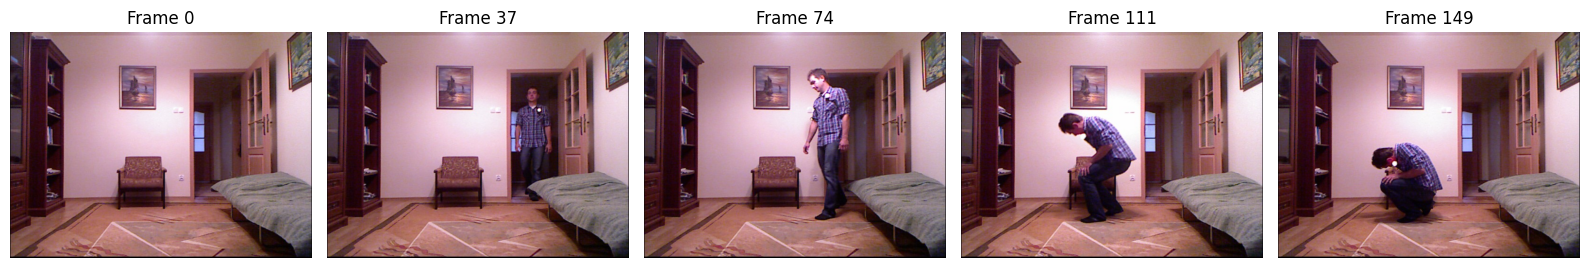

In [2]:
# ============================================================
# STEP 2: DATASET EXPLORATION
# ============================================================

from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np

DATASET_ROOT = Path(
    "/kaggle/input/datasets/shahliza27/ur-fall-detection-dataset/UR_fall_detection_dataset_cam0_rgb"
)

print("Dataset exists:", DATASET_ROOT.exists())

# Display top-level structure
print("\nTop-level contents:\n")

for item in sorted(DATASET_ROOT.iterdir()):
    print(item.name, "| Directory:", item.is_dir())

# Find all image sequence directories
image_extensions = {".png", ".jpg", ".jpeg", ".bmp"}

sequence_dirs = []

for folder in DATASET_ROOT.rglob("*"):
    if folder.is_dir():
        images = [
            f for f in folder.iterdir()
            if f.is_file() and f.suffix.lower() in image_extensions
        ]

        if images:
            sequence_dirs.append(folder)

print("\nTotal image sequence directories:", len(sequence_dirs))

# Inspect sequences
for folder in sequence_dirs[:15]:

    frames = sorted([
        f for f in folder.iterdir()
        if f.suffix.lower() in image_extensions
    ])

    print(folder.name, "| Frames:", len(frames))

# Visualize first sequence
if sequence_dirs:

    sample_dir = sequence_dirs[0]

    frames = sorted([
        f for f in sample_dir.iterdir()
        if f.suffix.lower() in image_extensions
    ])

    indices = np.linspace(
        0, len(frames)-1, min(5, len(frames)), dtype=int
    )

    plt.figure(figsize=(16, 4))

    for i, idx in enumerate(indices):

        image = cv2.imread(str(frames[idx]))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        plt.subplot(1, len(indices), i+1)
        plt.imshow(image)
        plt.title(f"Frame {idx}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

else:
    print("No image sequences detected.")

Total sequences: 70
Class distribution: Counter({0: 40, 1: 30})

Dataset split:
Training: 49
Validation: 10
Testing: 11

Processing training data...
Training: 5/49 processed
Training: 10/49 processed
Training: 15/49 processed
Training: 20/49 processed
Training: 25/49 processed
Training: 30/49 processed
Training: 35/49 processed
Training: 40/49 processed
Training: 45/49 processed
Training: 49/49 processed

Processing validation data...
Validation: 5/10 processed
Validation: 10/10 processed

Processing testing data...
Testing: 5/11 processed
Testing: 10/11 processed
Testing: 11/11 processed

========== FINAL DATASET ==========
X_train: (49, 16, 112, 112, 3)
y_train: (49,)
X_val: (10, 16, 112, 112, 3)
y_val: (10,)
X_test: (11, 16, 112, 112, 3)
y_test: (11,)

Class distribution:
Training: Counter({np.int32(0): 28, np.int32(1): 21})
Validation: Counter({np.int32(0): 6, np.int32(1): 4})
Testing: Counter({np.int32(0): 6, np.int32(1): 5})

Pixel range:
0.0 to 1.0


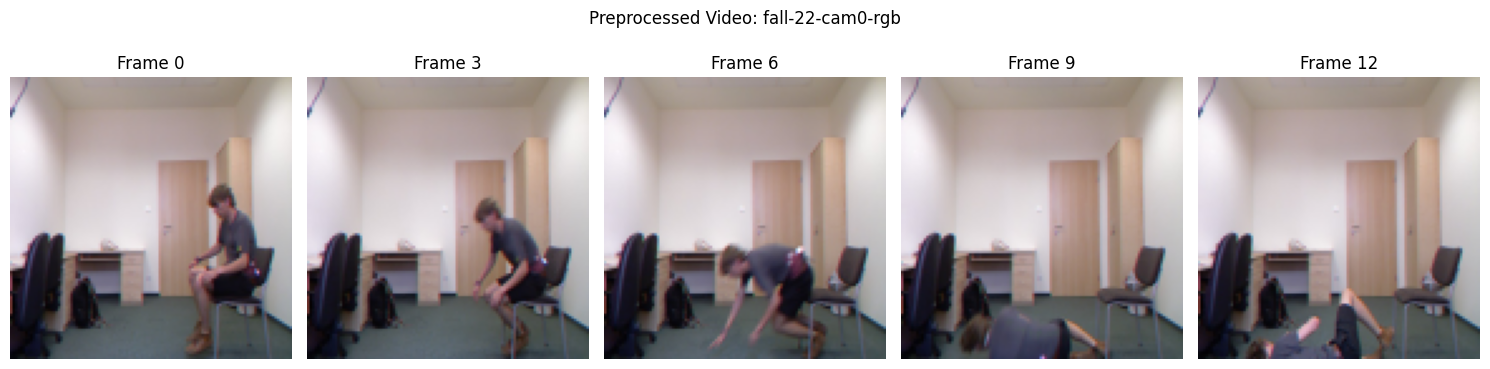


Preprocessing completed!


In [4]:

# ============================================================
# STEP 3: OPTIMIZED VIDEO PREPROCESSING
# ============================================================

import re
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split

# Configuration
IMG_SIZE = 112
NUM_FRAMES = 16
CHANNELS = 3

DATASET_ROOT = Path(
    "/kaggle/input/datasets/shahliza27/ur-fall-detection-dataset/UR_fall_detection_dataset_cam0_rgb"
)

cv2.setNumThreads(2)


# ------------------------------------------------------------
# 1. IDENTIFY SEQUENCES AND LABELS
# ------------------------------------------------------------

def natural_sort_key(path):
    return [
        int(text) if text.isdigit() else text.lower()
        for text in re.split(r'(\d+)', path.name)
    ]


sequence_data = []

for folder in DATASET_ROOT.iterdir():

    if not folder.is_dir():
        continue

    name = folder.name.lower()

    if name.startswith("fall"):
        label = 1

    elif name.startswith("adl"):
        label = 0

    else:
        continue

    frames = sorted(
        [
            f for f in folder.iterdir()
            if f.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp"}
        ],
        key=natural_sort_key
    )

    if len(frames) > 0:
        sequence_data.append({
            "name": folder.name,
            "frames": frames,
            "label": label
        })


print("Total sequences:", len(sequence_data))
print("Class distribution:", Counter(
    item["label"] for item in sequence_data
))


# ------------------------------------------------------------
# 2. STRATIFIED DATASET SPLITTING
# ------------------------------------------------------------

labels = np.array([item["label"] for item in sequence_data])
indices = np.arange(len(sequence_data))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=labels[temp_idx]
)

train_sequences = [sequence_data[i] for i in train_idx]
val_sequences = [sequence_data[i] for i in val_idx]
test_sequences = [sequence_data[i] for i in test_idx]

print("\nDataset split:")
print("Training:", len(train_sequences))
print("Validation:", len(val_sequences))
print("Testing:", len(test_sequences))


# ------------------------------------------------------------
# 3. FAST VIDEO PREPROCESSING
# ------------------------------------------------------------

def preprocess_video(sequence):

    frame_paths = sequence["frames"]

    # Select 16 evenly spaced frames
    indices = np.linspace(
        0,
        len(frame_paths) - 1,
        NUM_FRAMES,
        dtype=int
    )

    video_frames = []

    for idx in indices:

        image = cv2.imread(str(frame_paths[idx]))

        # Skip corrupted sequence if selected frame is invalid
        if image is None:
            return None

        # Convert BGR to RGB
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Resize
        image = cv2.resize(
            image,
            (IMG_SIZE, IMG_SIZE),
            interpolation=cv2.INTER_AREA
        )

        # Normalize
        image = image.astype(np.float32) / 255.0

        video_frames.append(image)

    return np.stack(video_frames, axis=0)


# ------------------------------------------------------------
# 4. CREATE TRAINING, VALIDATION AND TEST ARRAYS
# ------------------------------------------------------------

def create_dataset(sequences, name):

    X, y, names = [], [], []

    total = len(sequences)

    for i, sequence in enumerate(sequences):

        video = preprocess_video(sequence)

        if video is not None:

            X.append(video)
            y.append(sequence["label"])
            names.append(sequence["name"])

        if (i + 1) % 5 == 0 or i + 1 == total:
            print(f"{name}: {i+1}/{total} processed")

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.int32),
        names
    )


print("\nProcessing training data...")
X_train, y_train, train_names = create_dataset(
    train_sequences, "Training"
)

print("\nProcessing validation data...")
X_val, y_val, val_names = create_dataset(
    val_sequences, "Validation"
)

print("\nProcessing testing data...")
X_test, y_test, test_names = create_dataset(
    test_sequences, "Testing"
)


# ------------------------------------------------------------
# 5. DISPLAY FINAL DATASET SHAPES
# ------------------------------------------------------------

print("\n========== FINAL DATASET ==========")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nClass distribution:")
print("Training:", Counter(y_train))
print("Validation:", Counter(y_val))
print("Testing:", Counter(y_test))

print("\nPixel range:")
print(X_train.min(), "to", X_train.max())


# ------------------------------------------------------------
# 6. VISUALIZE PREPROCESSED VIDEO
# ------------------------------------------------------------

if len(X_train) > 0:

    sample_video = X_train[0]

    plt.figure(figsize=(15, 4))

    for i in range(5):

        frame_index = i * 3

        plt.subplot(1, 5, i + 1)
        plt.imshow(sample_video[frame_index])
        plt.title(f"Frame {frame_index}")
        plt.axis("off")

    plt.suptitle(
        f"Preprocessed Video: {train_names[0]}"
    )

    plt.tight_layout()
    plt.show()

else:
    print("No valid training videos found.")


print("\nPreprocessing completed!")


In [5]:

# ============================================================
# STEP 4: DATA AUGMENTATION AND CLASS BALANCING
# ============================================================

import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

BATCH_SIZE = 4

# Calculate class weights
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class weights:", class_weights)


# Augmentation function
def augment_video(video, label):

    # Random horizontal flip (same flip for all frames)
    video = tf.cond(
        tf.random.uniform([]) > 0.5,
        lambda: tf.reverse(video, axis=[2]),
        lambda: video
    )

    # Random spatial crop applied consistently to all frames
    crop_size = 100

    video = tf.image.random_crop(
        video,
        size=[NUM_FRAMES, crop_size, crop_size, CHANNELS]
    )

    # Resize cropped frames back to 112x112
    video = tf.image.resize(
        video,
        [IMG_SIZE, IMG_SIZE]
    )

    # Random brightness
    video = tf.image.random_brightness(
        video,
        max_delta=0.10
    )

    video = tf.clip_by_value(video, 0.0, 1.0)

    return video, label


# Training dataset
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

train_dataset = (
    train_dataset
    .shuffle(len(X_train), seed=42)
    .map(
        augment_video,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


# Validation dataset (NO augmentation)
val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

val_dataset = (
    val_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


# Testing dataset (NO augmentation)
test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

test_dataset = (
    test_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


print("\nData augmentation and balancing completed.")

print("Training batches:", len(train_dataset))
print("Validation batches:", len(val_dataset))
print("Testing batches:", len(test_dataset))


Class weights: {0: 0.875, 1: 1.1666666666666667}


I0000 00:00:1793463407.999150      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793463408.006615      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



Data augmentation and balancing completed.
Training batches: 13
Validation batches: 3
Testing batches: 3


In [9]:

# ============================================================
# STEP 5 (REVISED): SMALLER 3D CNN ARCHITECTURE
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

# Clear previous model
tf.keras.backend.clear_session()

INPUT_SHAPE = (
    NUM_FRAMES,
    IMG_SIZE,
    IMG_SIZE,
    CHANNELS
)

model = models.Sequential([

    layers.Input(shape=INPUT_SHAPE),

    # First convolution block
    layers.Conv3D(
        16,
        kernel_size=(3, 3, 3),
        padding="same",
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.MaxPooling3D(
        pool_size=(1, 2, 2)
    ),

    # Second convolution block
    layers.Conv3D(
        32,
        kernel_size=(3, 3, 3),
        padding="same",
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.MaxPooling3D(
        pool_size=(2, 2, 2)
    ),

    # Third convolution block
    layers.Conv3D(
        64,
        kernel_size=(3, 3, 3),
        padding="same",
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.MaxPooling3D(
        pool_size=(2, 2, 2)
    ),

    # Global feature extraction
    layers.GlobalAveragePooling3D(),

    # Classification layers
    layers.Dense(64, activation="relu"),

    layers.Dropout(0.4),

    layers.Dense(1, activation="sigmoid")
])


# Compile model
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

print("\nRevised 3D CNN created successfully!")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv3d (Conv3D)                 │ (None, 16, 112, 112,   │         1,312 │
│                                 │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 16, 56, 56, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 16, 56, 56, 32) │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 8, 28, 28, 32)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_2 (Conv3D)               │ (None, 8, 28, 28, 64)  │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_2 (MaxPooling3D)  │ (None, 4, 14, 14, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling3d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,753 (292.00 KB)

 Trainable params: 74,753 (292.00 KB)

 Non-trainable params: 0 (0.00 B)


Revised 3D CNN created successfully!


Epoch 1/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 287ms/step - accuracy: 0.4461 - auc: 0.5264 - loss: 0.7594 - precision: 0.3886 - recall: 0.4113
Epoch 1: val_loss improved from None to 0.75918, saving model to best_fall_detection_model_v2.keras

Epoch 1: finished saving model to best_fall_detection_model_v2.keras
13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 529ms/step - accuracy: 0.4082 - auc: 0.4464 - loss: 0.7640 - precision: 0.3333 - recall: 0.3810 - val_accuracy: 0.4000 - val_auc: 0.6667 - val_loss: 0.7592 - val_precision: 0.4000 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/40
11/13 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.6341 - auc: 0.5166 - loss: 0.7672 - precision: 0.5775 - recall: 0.8777
Epoch 2: val_loss improved from 0.75918 to 0.75718, saving model to best_fall_detection_model_v2.keras

Epoch 2: finished saving model to best_fall_detection_model_v2.keras
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.4694 - auc: 0.5068 - loss: 0.7605 - precision: 0.4359 - recall: 0.8095

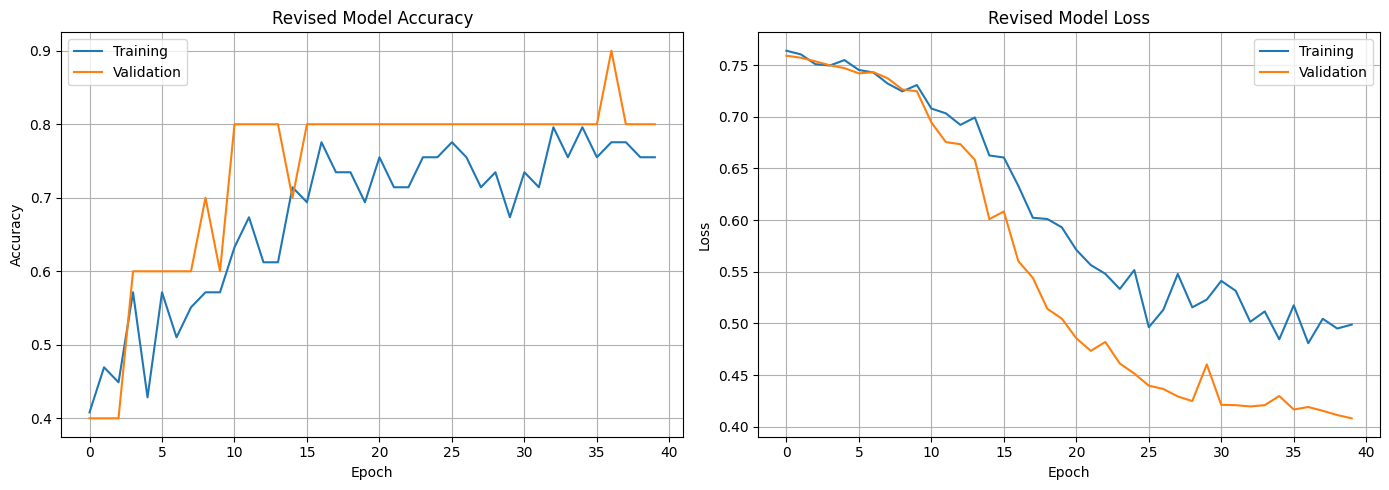

In [10]:

# ============================================================
# STEP 6 (REVISED): TRAIN SMALLER 3D CNN
# ============================================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

EPOCHS = 40

callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        "best_fall_detection_model_v2.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

history = model.fit(

    train_dataset,

    validation_data=val_dataset,

    epochs=EPOCHS,

    class_weight=class_weights,

    callbacks=callbacks,

    verbose=1
)


# Plot training history
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.title("Revised Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()


plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")

plt.title("Revised Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()


In [11]:

# ============================================================
# STEP 7: CHECK REVISED MODEL VALIDATION PREDICTIONS
# ============================================================

val_prob = model.predict(X_val, verbose=0).ravel()

val_pred = (val_prob >= 0.5).astype(int)

print("========== REVISED MODEL DIAGNOSTICS ==========")

print("\nActual distribution:")
print("Normal:", np.sum(y_val == 0))
print("Fall:", np.sum(y_val == 1))

print("\nPredicted distribution:")
print("Normal:", np.sum(val_pred == 0))
print("Fall:", np.sum(val_pred == 1))

print("\nProbability range:")
print("Minimum:", val_prob.min())
print("Maximum:", val_prob.max())
print("Mean:", val_prob.mean())

print("\nValidation confusion matrix:")
print(confusion_matrix(y_val, val_pred))

print("\nClassification report:")
print(classification_report(
    y_val,
    val_pred,
    target_names=["Normal", "Fall"],
    zero_division=0
))

# Display individual predictions
for i in range(len(y_val)):
    print(
        f"{val_names[i]} | "
        f"Actual: {y_val[i]} | "
        f"Probability: {val_prob[i]:.4f} | "
        f"Predicted: {val_pred[i]}"
    )


========== REVISED MODEL DIAGNOSTICS ==========

Actual distribution:
Normal: 6
Fall: 4

Predicted distribution:
Normal: 4
Fall: 6

Probability range:
Minimum: 0.006311738
Maximum: 0.68752754
Mean: 0.4004827

Validation confusion matrix:
[[4 2]
 [0 4]]

Classification report:
              precision    recall  f1-score   support

      Normal       1.00      0.67      0.80         6
        Fall       0.67      1.00      0.80         4

    accuracy                           0.80        10
   macro avg       0.83      0.83      0.80        10
weighted avg       0.87      0.80      0.80        10

adl-08-cam0-rgb | Actual: 0 | Probability: 0.0224 | Predicted: 0
adl-19-cam0-rgb | Actual: 0 | Probability: 0.0064 | Predicted: 0
fall-30-cam0-rgb | Actual: 1 | Probability: 0.6716 | Predicted: 1
fall-25-cam0-rgb | Actual: 1 | Probability: 0.6875 | Predicted: 1
fall-21-cam0-rgb | Actual: 1 | Probability: 0.6790 | Predicted: 1
fall-09-cam0-rgb | Actual: 1 | Probability: 0.6434 | Predicted: 1
ad

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 612ms/step - accuracy: 0.7273 - auc: 0.8500 - loss: 0.5047 - precision: 0.6250 - recall: 1.0000

========== TEST LOSS ==========
accuracy: 0.7273
auc: 0.8500
loss: 0.5047
precision: 0.6250
recall: 1.0000

========== FINAL TEST RESULTS ==========
Accuracy: 0.7273
Precision: 0.6250
Recall: 1.0000
F1-Score: 0.7692
AUROC: 0.8667

========== CLASSIFICATION REPORT ==========
                 precision    recall  f1-score   support

Normal Activity       1.00      0.50      0.67         6
           Fall       0.62      1.00      0.77         5

       accuracy                           0.73        11
      macro avg       0.81      0.75      0.72        11
   weighted avg       0.83      0.73      0.71        11


Confusion Matrix:
[[3 3]
 [0 5]]

True Negatives: 3
False Positives: 3
False Negatives: 0
True Positives: 5


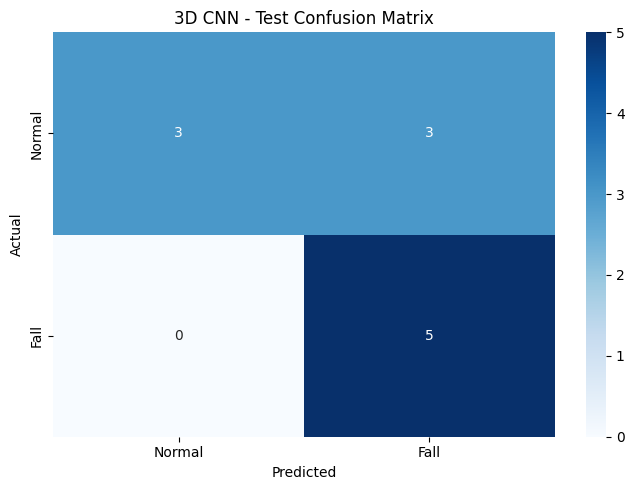

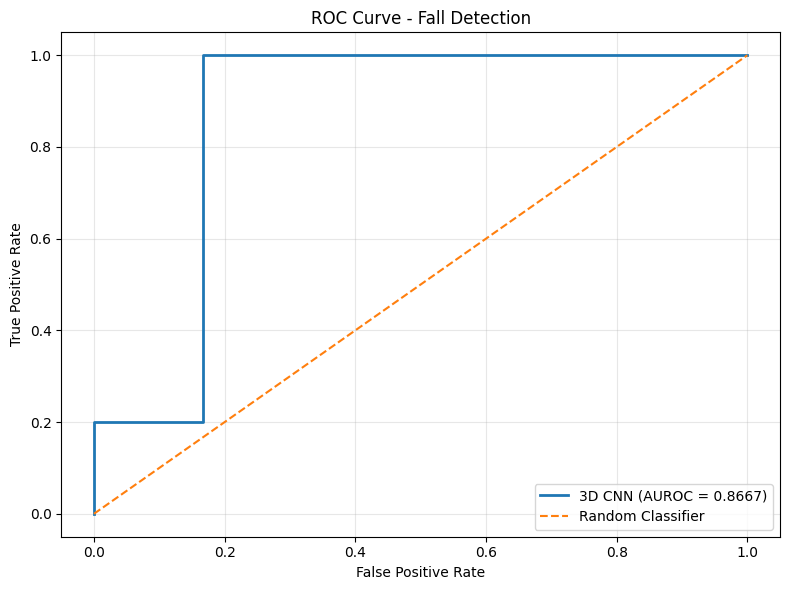


========== MISCLASSIFICATION ANALYSIS ==========
Total test videos: 11
Correct predictions: 8
Incorrect predictions: 3


,Video,Actual,Predicted,Fall Probability
0,adl-29-cam0-rgb,Normal,Fall,0.6901
1,adl-33-cam0-rgb,Normal,Fall,0.6263
2,adl-36-cam0-rgb,Normal,Fall,0.6031


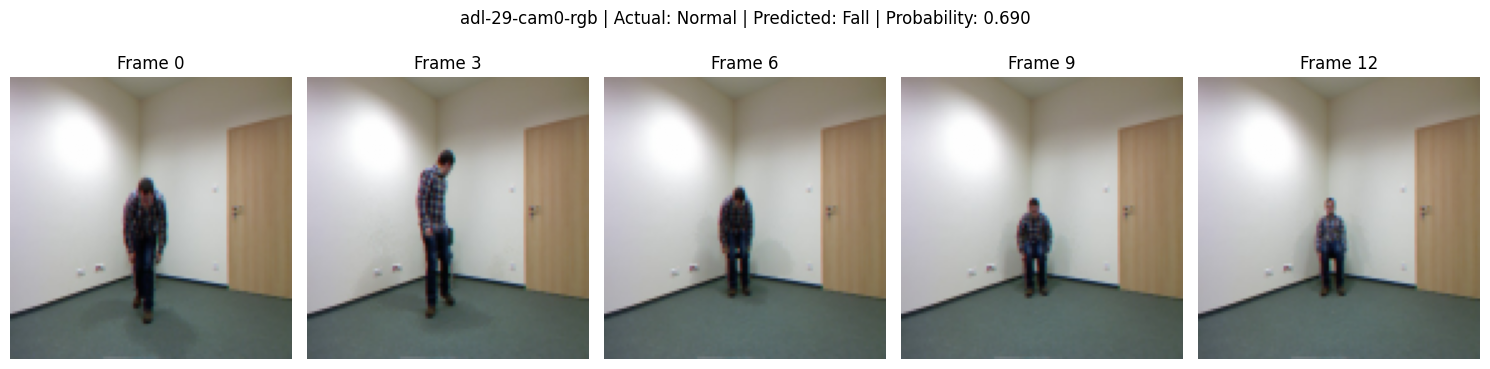

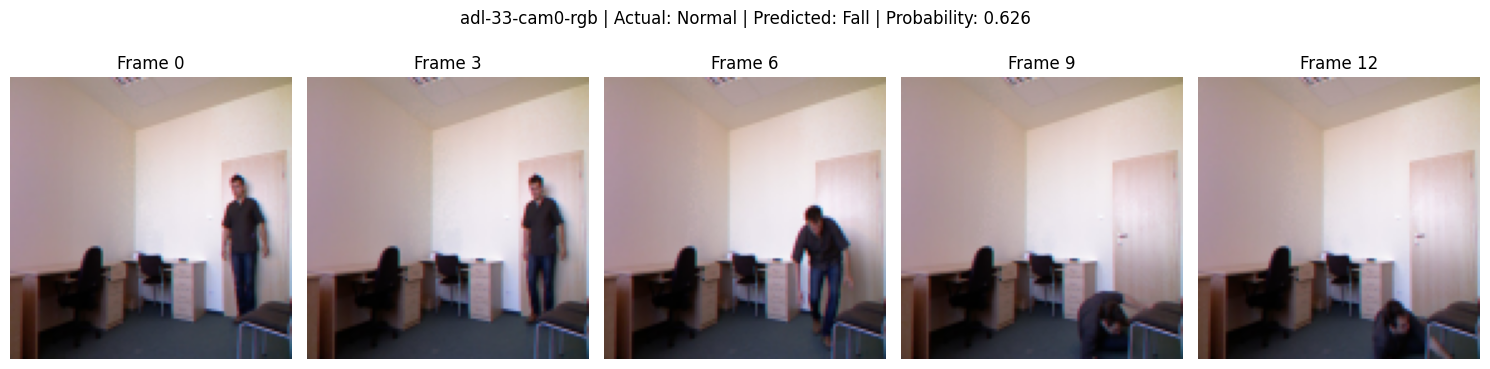

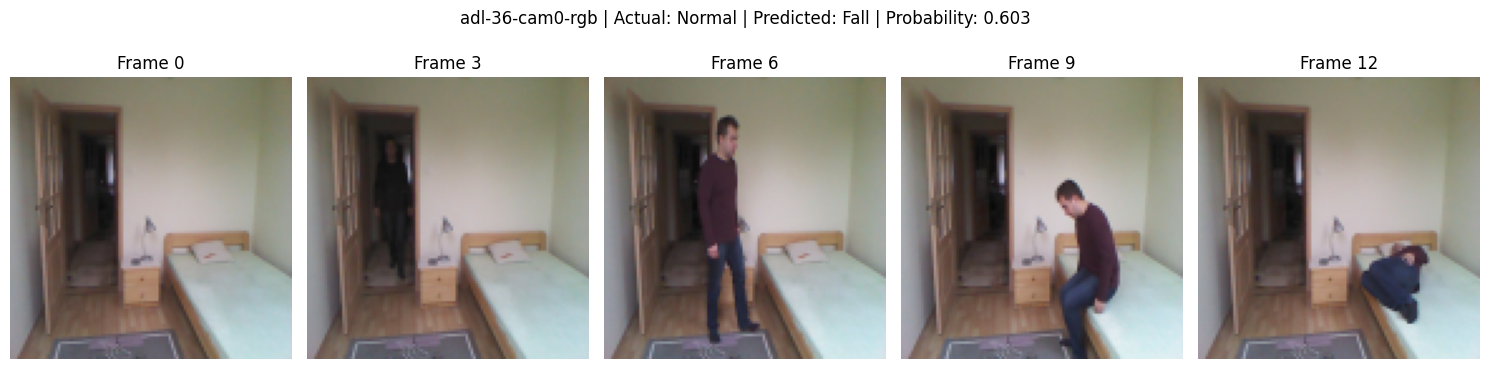


========== FINAL PERFORMANCE SUMMARY ==========


,Metric,Score
0,Accuracy,0.727273
1,Precision,0.625000
2,Recall,1.000000
3,F1-Score,0.769231
4,AUROC,0.866667


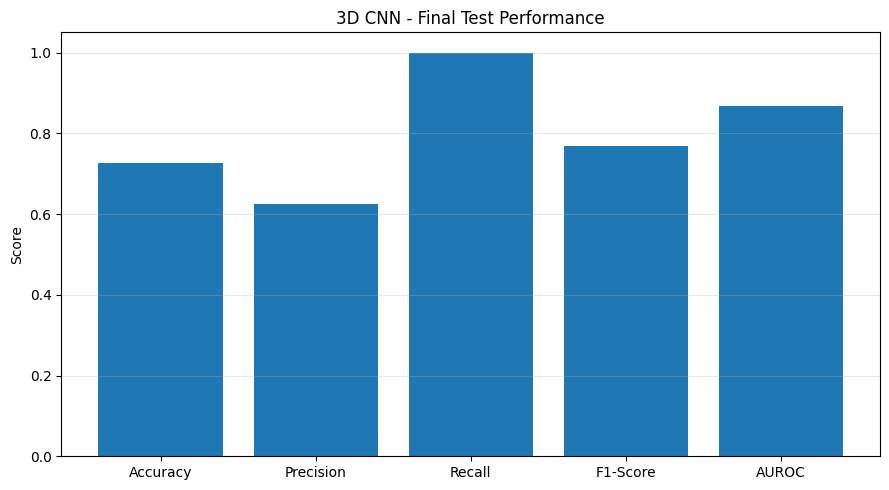


Fall Detection Experiment Completed!


In [12]:

# ============================================================
# STEP 8: FINAL TEST SET EVALUATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# ------------------------------------------------------------
# 1. EVALUATE MODEL ON TEST DATA
# ------------------------------------------------------------

test_results = model.evaluate(
    test_dataset,
    verbose=1,
    return_dict=True
)

print("\n========== TEST LOSS ==========")

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")


# ------------------------------------------------------------
# 2. GENERATE TEST PREDICTIONS
# ------------------------------------------------------------

y_prob = model.predict(
    test_dataset,
    verbose=0
).ravel()

THRESHOLD = 0.5

y_pred = (y_prob >= THRESHOLD).astype(int)


# ------------------------------------------------------------
# 3. CALCULATE PERFORMANCE METRICS
# ------------------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

auc = (
    roc_auc_score(y_test, y_prob)
    if len(np.unique(y_test)) == 2
    else np.nan
)


# ------------------------------------------------------------
# 4. DISPLAY FINAL METRICS
# ------------------------------------------------------------

results = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1,
    "AUROC": auc
}

print("\n========== FINAL TEST RESULTS ==========")

for name, value in results.items():
    print(f"{name}: {value:.4f}")


# ------------------------------------------------------------
# 5. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Normal Activity", "Fall"],
    zero_division=0
))


# ------------------------------------------------------------
# 6. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

print("\nConfusion Matrix:")
print(cm)

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fall"],
    yticklabels=["Normal", "Fall"]
)

plt.title("3D CNN - Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. ROC CURVE
# ------------------------------------------------------------

if len(np.unique(y_test)) == 2:

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )

    plt.figure(figsize=(8, 6))

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"3D CNN (AUROC = {auc:.4f})"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Random Classifier"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")

    plt.title("ROC Curve - Fall Detection")

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 8. IDENTIFY MISCLASSIFIED VIDEOS
# ------------------------------------------------------------

misclassified_indices = np.where(y_test != y_pred)[0]

print("\n========== MISCLASSIFICATION ANALYSIS ==========")

print("Total test videos:", len(y_test))
print("Correct predictions:", np.sum(y_test == y_pred))
print("Incorrect predictions:", len(misclassified_indices))

error_data = []

for idx in misclassified_indices:

    error_data.append({
        "Video": test_names[idx],
        "Actual": "Fall" if y_test[idx] == 1 else "Normal",
        "Predicted": "Fall" if y_pred[idx] == 1 else "Normal",
        "Fall Probability": round(float(y_prob[idx]), 4)
    })

error_df = pd.DataFrame(error_data)

display(error_df)


# ------------------------------------------------------------
# 9. VISUALIZE MISCLASSIFIED VIDEOS
# ------------------------------------------------------------

for idx in misclassified_indices[:5]:

    video = X_test[idx]

    actual = "Fall" if y_test[idx] == 1 else "Normal"
    predicted = "Fall" if y_pred[idx] == 1 else "Normal"

    plt.figure(figsize=(15, 4))

    for i in range(5):

        frame_index = i * 3

        plt.subplot(1, 5, i + 1)
        plt.imshow(video[frame_index])

        plt.title(f"Frame {frame_index}")
        plt.axis("off")

    plt.suptitle(
        f"{test_names[idx]} | Actual: {actual} | "
        f"Predicted: {predicted} | "
        f"Probability: {y_prob[idx]:.3f}"
    )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 10. FINAL PERFORMANCE TABLE
# ------------------------------------------------------------

final_results = pd.DataFrame({
    "Metric": list(results.keys()),
    "Score": list(results.values())
})

print("\n========== FINAL PERFORMANCE SUMMARY ==========")

display(final_results)

plt.figure(figsize=(9, 5))

plt.bar(
    final_results["Metric"],
    final_results["Score"]
)

plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("3D CNN - Final Test Performance")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nFall Detection Experiment Completed!")
